**Live cloud deployment: PENDING - account sign-in and public verification required.**

This is an explicit status, not a deployment link. The instructor demo is not this submission.

# Heart Disease Prediction System
**Assignment 2 - Developing an End-to-End Machine Learning System**

**Student:** Muhammad Bilal Nawaz | **Registration:** SP24-BSE-070  
**Course:** AIC354 - Machine Learning Fundamentals | **Semester:** Fall 2026  
**Instructor:** Dr. Rao Muhammad Adeel Nawab | COMSATS University Islamabad, Lahore Campus

This notebook implements data collection, understanding, preprocessing and encoding, followed by the training, testing, application and feedback phases. All experiments and saved artifacts are produced by running the cells in order.

## Source, scope and reproducibility
Adapted from the assignment-provided [Titanic Recommended notebook](https://github.com/haqnawaz99/ml-teaching-notebooks), commit `c5f67db8361bd8953c4facf9e5ab98ce9242f314`. Original teaching material credits Mr. Mohsin Afzal and Dr. Rao Muhammad Adeel Nawab. This submission retains the source step sequence and SVC approach, with explicit changes below. Source material is credited; AI-assisted implementation was reviewed through executable checks.

Run **Kernel > Restart Kernel and Run All Cells** from this task folder. Install the parent `requirements-notebook.txt` first. Data are included locally, so training does not need network access. See `../PROVENANCE.json` for data hashes and `../README.md` for deployment and execution commands.

## Workflow
1. Import libraries
2. Load sample data
3. Understand and preprocess data
4. Extract/select features
5. Encode output and inputs
6. Training phase: split, fit and save
7. Testing phase: reload, predict and evaluate
8. Application phase: new input to prediction
9. Feedback phase: review findings and plan improvements
10. Generate the deployment app and verify its status

## Problem and four-input specification
Predict the binary **recorded presence of heart disease** in the processed Cleveland dataset. This is a classroom classification experiment, not a clinical decision tool.

| Input | Meaning / units | Raw values | Treatment |
|---|---|---|---|
| `age` | Age in years | Numeric | Median imputation and scaling |
| `cp` | Chest-pain type | 1 typical angina; 2 atypical; 3 non-anginal; 4 asymptomatic | Fixed label encoding |
| `thalach` | Maximum heart rate achieved, beats/min | Numeric | Median imputation and scaling |
| `exang` | Exercise-induced angina | 0 no; 1 yes | Fixed label encoding |

These four attributes were chosen before evaluation to combine demographic, symptom and exercise information while complying with the assignment. Their choice is not a claim that they are the optimal four. `num` is the source target, never an input: 0 maps to absence; 1-4 map to presence. Numeric measurements are not label-encoded because that would discard their meaningful distances.

**Adaptations from Titanic:** load UCI data and recognize `?` as missing; select four columns; map the target; use a reproducible stratified split; add training-only imputation/scaling for numeric units. The same SVC (`gamma='auto'`, `random_state=0`) and the same numbered workflow are retained. Ordinal coding of the nominal `cp` categories is a limitation of preserving the teaching approach.

### Step 1: Import Libraries

In [1]:
TASK = 'Heart_Disease'

from pathlib import Path
import hashlib, json, pickle, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             balanced_accuracy_score, roc_auc_score, RocCurveDisplay)
BASE = Path.cwd()
if not (BASE / 'data').is_dir():
    candidate = BASE / TASK
    if not candidate.is_dir():
        candidate = BASE / 'submission' / TASK
    BASE = candidate
assert (BASE / 'data').is_dir(), 'Open this notebook from its task folder or submission folder.'
for name in ['models', 'outputs']:
    (BASE / name).mkdir(exist_ok=True)
pd.set_option('display.max_rows', 16)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

Python: 3.14.6 | scikit-learn: 1.9.1


### Step 2: Load Sample Data
Official source: [UCI Heart Disease, dataset 45](https://archive.ics.uci.edu/dataset/45/heart+disease). The downloaded archive contains multiple hospitals. Only `processed.cleveland.data` is used; hospitals are not mixed. Its 303 records have 13 potential predictors and one target.

Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1989). *Heart Disease* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X. License: CC BY 4.0.

In [2]:
columns = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal','num']
source_path = BASE / 'data/processed.cleveland.data'
raw = pd.read_csv(source_path, names=columns, na_values='?')
assert raw.shape == (303, 14)
raw.to_csv(BASE / 'data/heart_cleveland.csv', index=False)
print('Rows, columns:', raw.shape)
print('Source SHA256:', hashlib.sha256(source_path.read_bytes()).hexdigest())
display(raw.head())

Rows, columns: (303, 14)
Source SHA256: a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### Step 3: Understand and Pre-process Sample Data
#### Step 3.1: Understand Sample Data

In [3]:
raw.info()
display(raw.describe().round(2))
display(raw.isna().sum().rename('Missing values').to_frame())
print('Exact duplicate complete records:', int(raw.duplicated().sum()))
print('Original target distribution:')
display(raw['num'].value_counts().sort_index().to_frame('Rows'))

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,299.00,301.00,303.00
mean,54.44,0.68,3.16,131.69,246.69,0.15,0.99,149.61,0.33,1.04,1.60,0.67,4.73,0.94
std,9.04,0.47,0.96,17.60,51.78,0.36,0.99,22.88,0.47,1.16,0.62,0.94,1.94,1.23
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.50,0.00,0.00,1.00,0.00,3.00,0.00
50%,56.00,1.00,3.00,130.00,241.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00
75%,61.00,1.00,4.00,140.00,275.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,2.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,4.00


,Missing values
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Exact duplicate complete records: 0
Original target distribution:


,Rows
num,
0,164
1,55
2,36
3,35
4,13


#### Step 3.2: Pre-process Sample Data
The loader converts `?` to missing values. Missingness is audited over all 14 columns, but only the four selected inputs matter for the model. No rows are removed merely because an unused attribute is missing. A missing target cannot train supervised learning, so it is checked explicitly. Imputation statistics will be learned after splitting, within the training pipeline.

In [4]:
assert raw['num'].notna().all()
assert set(raw['num'].unique()) <= {0, 1, 2, 3, 4}
data = raw.copy()
data['Disease'] = (data['num'] > 0).astype(int)
assert set(data['cp'].dropna().unique()) <= {1, 2, 3, 4}
assert set(data['exang'].dropna().unique()) <= {0, 1}
display(data[['num','Disease']].drop_duplicates().sort_values('num'))

,num,Disease
0,0,0
2,1,1
1,2,1
6,3,1
24,4,1


### Step 4: Feature Extraction
Select exactly four inputs; the target is stored separately.

,age,cp,thalach,exang,Disease
0,63.0,1.0,150.0,0.0,0
1,67.0,4.0,108.0,1.0,1
2,67.0,4.0,129.0,1.0,1
3,37.0,3.0,187.0,0.0,0
4,41.0,2.0,172.0,0.0,0


,Missing selected values
age,0
cp,0
thalach,0
exang,0
Disease,0


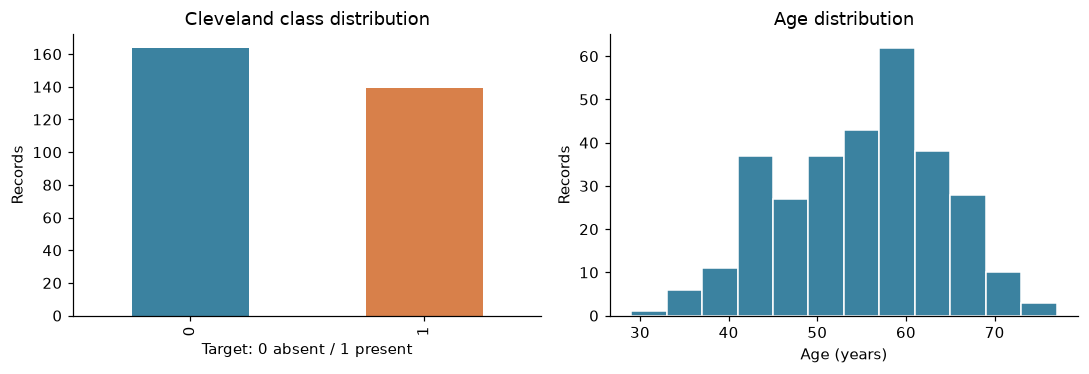

In [5]:
FEATURES = ['age', 'cp', 'thalach', 'exang']
TARGET = 'Disease'
assert len(FEATURES) == 4 and TARGET not in FEATURES and 'num' not in FEATURES
sample = data[FEATURES + [TARGET]].copy()
sample.to_csv(BASE / 'data/heart_four_inputs.csv', index=False)
display(sample.head())
display(sample.isna().sum().to_frame('Missing selected values'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sample[TARGET].value_counts().sort_index().plot.bar(ax=axes[0], color=['#3b82a0','#d8804a'])
axes[0].set(xlabel='Target: 0 absent / 1 present', ylabel='Records', title='Cleveland class distribution')
axes[1].hist(sample['age'], bins=12, color='#3b82a0', edgecolor='white')
axes[1].set(xlabel='Age (years)', ylabel='Records', title='Age distribution')
plt.tight_layout(); plt.savefig(BASE / 'outputs/data_overview.png'); plt.show()

### Step 5: Label Encoding the Sample Data
#### Steps 5.1-5.3: Define encoders, encode output, encode input
The output is already binary after the documented `num > 0` mapping. Encoders use fixed UCI category definitions, not categories discovered from the test set. Age and heart rate remain numeric. The encoder and scaler are reused for every future input.

In [6]:
category_schema = {'cp': [1, 2, 3, 4], 'exang': [0, 1]}
encoders = {name: LabelEncoder().fit(values) for name, values in category_schema.items()}
encoded = sample.copy()
for name, encoder in encoders.items():
    present = encoded[name].notna()
    encoded.loc[present, name] = encoder.transform(encoded.loc[present, name])
    print(name, dict(zip(encoder.classes_.tolist(), range(len(encoder.classes_)))))
encoded.to_csv(BASE / 'outputs/sample-data-encoded.csv', index_label='source_row')
display(encoded.head())

cp {1: 0, 2: 1, 3: 2, 4: 3}
exang {0: 0, 1: 1}


,age,cp,thalach,exang,Disease
0,63.0,0.0,150.0,0.0,0
1,67.0,3.0,108.0,1.0,1
2,67.0,3.0,129.0,1.0,1
3,37.0,2.0,187.0,0.0,0
4,41.0,1.0,172.0,0.0,0


### Step 6: Execute the Training Phase
#### Steps 6.1-6.2: Split and separate inputs/labels
A fixed, stratified 80/20 split preserves class proportions. The final test set is not used to select the four features or tune parameters. Source row indices make separation auditable. This intentionally replaces the source's ordered split for this different dataset.

In [7]:
train_idx, test_idx = train_test_split(encoded.index, test_size=0.2, random_state=42, stratify=encoded[TARGET])
X_train, X_test = encoded.loc[train_idx, FEATURES], encoded.loc[test_idx, FEATURES]
y_train, y_test = encoded.loc[train_idx, TARGET], encoded.loc[test_idx, TARGET]
assert set(train_idx).isdisjoint(test_idx)
assert len(train_idx) + len(test_idx) == len(encoded)

#### Step 6.3: Train the Support Vector Classifier
The pipeline fits median imputation and standardization on the training data only. Standardization prevents heart rate/age units dominating SVC distances. The default C=1 and RBF kernel are fixed; no search against the test set is performed.

In [8]:
model = Pipeline([('imputer', SimpleImputer(strategy='median')),
                  ('scaler', StandardScaler()),
                  ('svc', SVC(gamma='auto', random_state=0))])
model.fit(X_train, y_train)
assert model.n_features_in_ == 4
print(model)
print('Training-only imputer medians:', model.named_steps['imputer'].statistics_)
print('Training-only scaler means:', model.named_steps['scaler'].mean_)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('svc', SVC(gamma='auto', random_state=0))])
Training-only imputer medians: [ 56.    2.  153.5   0. ]
Training-only scaler means: [ 54.54958678   2.15289256 149.96280992   0.32644628]


In [9]:
print('Training inputs:', X_train.shape, '| Testing inputs:', X_test.shape)
display(pd.DataFrame({'Train': y_train.value_counts(), 'Test': y_test.value_counts()}).sort_index())
encoded.loc[train_idx].to_csv(BASE / 'outputs/training-data-encoded.csv', index_label='source_row')
encoded.loc[test_idx].to_csv(BASE / 'outputs/testing-data-encoded.csv', index_label='source_row')

Training inputs: (242, 4) | Testing inputs: (61, 4)


,Train,Test
Disease,,
0,131,33
1,111,28


#### Step 6.4: Save the Trained Model
Save model, encoders, feature order, target labels, source and package versions together. Inference must reuse exactly the training transformations. Only load trusted model files: pickle can execute code.

In [10]:
bundle = {'task': TASK, 'features': FEATURES, 'model': model, 'encoders': encoders,
          'labels': {0: "Disease absent", 1: "Disease present"},
          'source_url': "https://archive.ics.uci.edu/dataset/45/heart+disease",
          'sklearn_version': sklearn.__version__, 'training_rows': len(X_train),
          'observed_ranges': {name: [float(sample.loc[train_idx,name].min()), float(sample.loc[train_idx,name].max())] for name in ['age', 'thalach'] } }
model_path = BASE / 'models/model_bundle.pkl'
with model_path.open('wb') as stream:
    pickle.dump(bundle, stream)
print('Saved:', model_path.name)

Saved: model_bundle.pkl


### Step 7: Execute the Testing Phase
#### Steps 7.1-7.3: Reload model and predict held-out inputs
Test features/labels were separated at the split. Reload from disk and compare predictions against the in-memory model to verify serialization.

In [11]:
with model_path.open('rb') as stream:
    loaded = pickle.load(stream)
predictions = loaded['model'].predict(X_test)
np.testing.assert_array_equal(predictions, model.predict(X_test))
prediction_table = sample.loc[test_idx].copy()
prediction_table['Actual_binary'] = y_test
prediction_table['Predicted_binary'] = predictions
prediction_table['Correct'] = predictions == y_test.to_numpy()
prediction_table.to_csv(BASE / 'outputs/model-predictions.csv', index_label='source_row')
display(prediction_table.head(12))

,age,cp,thalach,exang,Disease,Actual_binary,Predicted_binary,Correct
219,59.0,4.0,182.0,0.0,0,0,0,True
271,66.0,4.0,138.0,0.0,0,0,1,False
89,51.0,3.0,149.0,0.0,0,0,0,True
101,34.0,1.0,174.0,0.0,0,0,0,True
67,54.0,3.0,165.0,0.0,0,0,0,True
244,60.0,3.0,96.0,0.0,0,0,1,False
185,63.0,2.0,179.0,0.0,0,0,0,True
233,74.0,2.0,121.0,1.0,0,0,1,False
168,35.0,4.0,156.0,1.0,1,1,1,True
197,45.0,4.0,152.0,1.0,0,0,1,False


#### Steps 7.4-7.5: Accuracy and Detailed Evaluation
Precision, recall and F1 below treat class 1 as positive. Compare accuracy with a baseline fitted to the training majority. ROC AUC uses SVC decision scores, not calibrated probabilities. Test outcomes describe this particular sample and split.

,Result
accuracy,0.786885
precision,0.826087
recall,0.678571
f1,0.745098
balanced_accuracy,0.778680
roc_auc,0.896104
majority_baseline_accuracy,0.540984
train_rows,242.000000
test_rows,61.000000


                 precision    recall  f1-score   support

 Disease absent       0.76      0.88      0.82        33
Disease present       0.83      0.68      0.75        28

       accuracy                           0.79        61
      macro avg       0.79      0.78      0.78        61
   weighted avg       0.79      0.79      0.78        61



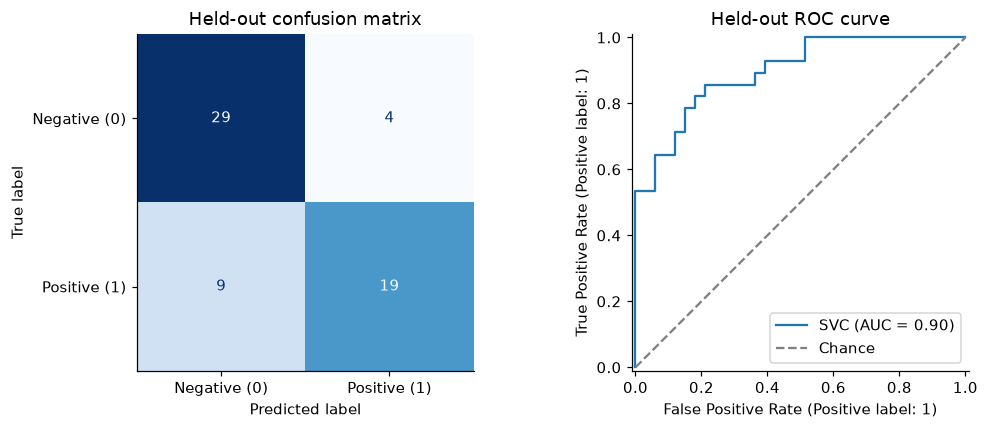

**Observed result:** 48/61 correct (78.7% accuracy), versus 54.1% majority baseline. Confusion counts: TN=29, FP=4, FN=9, TP=19. Positive-class recall=67.9%; F1=0.745. These are measured outputs, not an expected-score target.

In [12]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
scores = loaded['model'].decision_function(X_test)
metrics = {
    'accuracy': float(accuracy_score(y_test, predictions)),
    'precision': float(precision_score(y_test, predictions, zero_division=0)),
    'recall': float(recall_score(y_test, predictions, zero_division=0)),
    'f1': float(f1_score(y_test, predictions, zero_division=0)),
    'balanced_accuracy': float(balanced_accuracy_score(y_test, predictions)),
    'roc_auc': float(roc_auc_score(y_test, scores)),
    'majority_baseline_accuracy': float(accuracy_score(y_test, baseline.predict(X_test))),
    'train_rows': len(X_train), 'test_rows': len(X_test),
    'confusion_matrix': confusion_matrix(y_test, predictions, labels=[0,1]).tolist()
}
display(pd.Series({k:v for k,v in metrics.items() if k != 'confusion_matrix'}, name='Result').to_frame())
print(classification_report(y_test, predictions, labels=[0,1], target_names=[bundle['labels'][0], bundle['labels'][1]], zero_division=0))
(BASE / 'outputs/metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
bundle['metrics'] = metrics
with model_path.open('wb') as stream:
    pickle.dump(bundle, stream)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=[0,1], display_labels=['Negative (0)','Positive (1)'], ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Held-out confusion matrix')
RocCurveDisplay.from_predictions(y_test, scores, ax=axes[1], name='SVC')
axes[1].plot([0,1], [0,1], '--', color='gray', label='Chance'); axes[1].legend()
axes[1].set_title('Held-out ROC curve')
plt.tight_layout(); plt.savefig(BASE / 'outputs/evaluation.png'); plt.show()
tn, fp, fn, tp = metrics['confusion_matrix'][0] + metrics['confusion_matrix'][1]
display(Markdown(f"**Observed result:** {int((predictions == y_test).sum())}/{len(y_test)} correct "
    f"({metrics['accuracy']:.1%} accuracy), versus {metrics['majority_baseline_accuracy']:.1%} majority baseline. "
    f"Confusion counts: TN={tn}, FP={fp}, FN={fn}, TP={tp}. Positive-class recall={metrics['recall']:.1%}; "
    f"F1={metrics['f1']:.3f}. These are measured outputs, not an expected-score target."))

### Step 8: Execute the Application Phase
#### Steps 8.1-8.5: Input, feature vector, encoding, reload and prediction
The deterministic example allows unattended Run All. Change the four values to explore another case. The web app provides interactive widgets. No model is fitted during prediction.

In [13]:
user_values = {'age': 54, 'cp': 4, 'thalach': 150, 'exang': 1}
user_input = pd.DataFrame([user_values], columns=FEATURES)
unseen = user_input.copy()
with model_path.open('rb') as stream:
    deployed_bundle = pickle.load(stream)
for name, encoder in deployed_bundle['encoders'].items():
    assert unseen.at[0,name] in encoder.classes_, 'Unknown category'
    unseen[name] = encoder.transform(unseen[name])
prediction = int(deployed_bundle['model'].predict(unseen)[0])
display(user_input)
display(unseen)
print('Prediction:', deployed_bundle['labels'][prediction], '(class', prediction, ')')

,age,cp,thalach,exang
0,54,4,150,1


,age,cp,thalach,exang
0,54,3,150,1


Prediction: Disease present (class 1 )


### Step 9: Execute the Feedback Phase
#### Step 9.1: Collect Feedback from Users and Domain Experts
No external user/domain-expert feedback has yet been collected. The observations below come from local execution and evaluation, not invented interviews. A blank feedback template is saved for later review; real entries should record case, predicted class, verified outcome, reviewer role and proposed action without personal data.

**Current limitations:** Small, historic single-center sample; a four-input restriction omits other information. False negatives are especially concerning if someone misuses this teaching model as a diagnosis. Sex is excluded as an input and performance by demographic group is not established. Coded chest-pain categories impose an artificial ordering; one-hot encoding is a future comparison while retaining four source attributes.

#### Step 9.2: Potential Improvements
- Review false positives and false negatives in the saved per-row predictions.
- Validate on additional independent data before claiming generalization.
- Compare representations and SVC settings using cross-validation within training data; preserve a separate final evaluation set.
- Collect usability feedback on units, category descriptions and validation messages.

#### Step 9.3: Act on Feedback
Implemented engineering improvements: saved preprocessing, fixed feature order, explicit input validation, honest class labels and reload consistency checks. No post-test retraining is performed or claimed to improve accuracy. A future model update requires documented feedback and fresh evaluation. The four-input constraint remains in force.

In [14]:
feedback_columns = ['case_id','reviewer_role','predicted_class','verified_outcome','comment','proposed_action']
feedback_path = BASE / 'outputs/feedback_template.csv'
if not feedback_path.exists():
    pd.DataFrame(columns=feedback_columns).to_csv(feedback_path, index=False)
mistakes = prediction_table.loc[~prediction_table['Correct']]
print('Held-out errors available for review:', len(mistakes))
display(mistakes.head(10))
print('Real external feedback collected: 0; template:', feedback_path.name)

Held-out errors available for review: 13


,age,cp,thalach,exang,Disease,Actual_binary,Predicted_binary,Correct
271,66.0,4.0,138.0,0.0,0,0,1,False
244,60.0,3.0,96.0,0.0,0,0,1,False
233,74.0,2.0,121.0,1.0,0,0,1,False
197,45.0,4.0,152.0,1.0,0,0,1,False
137,62.0,2.0,103.0,0.0,1,1,0,False
23,58.0,3.0,173.0,0.0,1,1,0,False
6,62.0,4.0,160.0,0.0,1,1,0,False
104,49.0,3.0,139.0,0.0,1,1,0,False
157,58.0,4.0,171.0,0.0,1,1,0,False
66,60.0,3.0,155.0,0.0,1,1,0,False


Real external feedback collected: 0; template: feedback_template.csv


### Step 10: Deploy the Model as a Public Web App
The next cell writes the complete Streamlit entry point. It loads the trained bundle and reuses its encoders/pipeline. The UI supplies exactly the four declared features.

Run from this task folder: `python -m streamlit run app.py`.

Upload the submission folder contents to a GitHub repository. In Streamlit Community Cloud create a public app, choose the repository, select this task's `app.py` and use Python 3.14. Deploy each task as a separate app from the same repository. The pinned dependency files accompany both apps. Full instructions are in the parent README. After verifying the public prediction, replace the first cell's pending status with the actual URL and update `deployment_status.json`.

Local execution alone does not satisfy the cloud requirement. The instructor's demo URL must not be substituted for a personal deployment.

In [15]:
app_source = '"""Generated by Step 10 of the corresponding assignment notebook."""\nfrom pathlib import Path\nimport math\nimport pickle\nimport pandas as pd\nimport streamlit as st\n\nTASK = \'Heart_Disease\'\nBASE = Path(__file__).resolve().parent\nst.set_page_config(page_title=TASK.replace(\'_\', \' \') + \' Predictor\', page_icon=\'📊\', layout=\'centered\')\n\n@st.cache_resource\ndef load_bundle(model_file):\n    with Path(model_file).open(\'rb\') as stream:\n        return pickle.load(stream)\n\ndef predict(values, bundle):\n    if set(values) != set(bundle[\'features\']):\n        raise ValueError(\'Provide exactly the four required inputs.\')\n    row = pd.DataFrame([values], columns=bundle[\'features\'])\n    if TASK == \'Heart_Disease\':\n        for field, low, high in [(\'age\', 1, 120), (\'thalach\', 30, 250)]:\n            value = float(row.at[0, field])\n            if not math.isfinite(value) or not low <= value <= high or not value.is_integer():\n                raise ValueError(f\'{field} must be a whole number from {low} to {high}.\')\n            row[field] = value\n    for field, encoder in bundle[\'encoders\'].items():\n        if row.at[0, field] not in encoder.classes_:\n            raise ValueError(f\'Invalid category for {field}.\')\n        row[field] = encoder.transform(row[field])\n    label = int(bundle[\'model\'].predict(row)[0])\n    return label, bundle[\'labels\'][label]\n\nst.title(\'Titanic Survival Predictor\' if TASK == \'Titanic\' else \'Heart Disease Predictor\')\nst.caption(\'AIC354 · Assignment 2 · Muhammad Bilal Nawaz · SP24-BSE-070\')\nbundle = load_bundle(str(BASE / \'models/model_bundle.pkl\'))\nif TASK == \'Heart_Disease\':\n    st.info(\'Educational demonstration using historical UCI data. This is not a medical diagnosis.\')\n    st.write(\'Enter four attributes to run the trained classifier.\')\nelse:\n    st.write(\'Explore a classifier trained on the instructor’s 100-passenger teaching sample.\')\n\nwith st.form(\'prediction_form\'):\n    if TASK == \'Titanic\':\n        values = {\n            \'PClass\': st.selectbox(\'Passenger class\', [\'First\', \'Second\', \'Third\']),\n            \'Gender\': st.selectbox(\'Gender\', [\'Male\', \'Female\']),\n            \'Sibling\': st.selectbox(\'Siblings / spouses aboard\', [\'Zero\', \'One\', \'Two\', \'Three\']),\n            \'Embarked\': st.selectbox(\'Embarkation port\', [\'Southampton\', \'Cherbourg\', \'Queenstown\'])\n        }\n    else:\n        pain = {1: \'Typical angina\', 2: \'Atypical angina\', 3: \'Non-anginal pain\', 4: \'Asymptomatic\'}\n        values = {\n            \'age\': st.number_input(\'Age (years)\', min_value=1, max_value=120, value=54, step=1),\n            \'cp\': st.selectbox(\'Chest-pain type\', [1, 2, 3, 4], format_func=lambda x: pain[x]),\n            \'thalach\': st.number_input(\'Maximum heart rate achieved (beats/min)\', min_value=30, max_value=250, value=150, step=1),\n            \'exang\': st.selectbox(\'Exercise-induced angina\', [0, 1], format_func=lambda x: \'Yes\' if x else \'No\')\n        }\n    submitted = st.form_submit_button(\'Predict\', type=\'primary\')\nif submitted:\n    try:\n        label, wording = predict(values, bundle)\n        st.success(\'Model prediction: \' + wording)\n        st.caption(\'Predicted class: \' + str(label) + \'. This is a class label, not a probability.\')\n        if TASK == \'Heart_Disease\' and any(not bounds[0] <= values[field] <= bounds[1] for field, bounds in bundle[\'observed_ranges\'].items()):\n            st.warning(\'An input is outside the training data range; this prediction may be unreliable.\')\n    except (ValueError, TypeError) as error:\n        st.error(str(error))\nwith st.expander(\'Model and evaluation\'):\n    st.write(\'Inputs:\', \', \'.join(bundle[\'features\']))\n    st.write(\'Held-out test accuracy:\', f"{bundle[\'metrics\'][\'accuracy\']:.1%}")\n    st.write(\'Test rows:\', bundle[\'metrics\'][\'test_rows\'])\n    st.write(\'Small historical datasets limit generalization. No live feedback has been used to retrain this model.\')\n    st.markdown(\'[Data and notebook source](\' + bundle[\'source_url\'] + \')\')\nst.caption(\'Inputs are used for this prediction only; the app does not write patient or passenger records.\')\n'
(BASE / 'app.py').write_text(app_source, encoding='utf-8')
print('Generated app.py:', len(app_source), 'characters')

Generated app.py: 4041 characters


In [16]:
status_path = BASE.parent / 'deployment_status.json'
status = json.loads(status_path.read_text(encoding='utf-8')) if status_path.exists() else {}
print(json.dumps(status.get(TASK, {'status':'pending', 'url':None}), indent=2))
assert list(bundle['features']) == FEATURES and len(FEATURES) == 4
assert set(train_idx).isdisjoint(test_idx)
assert model_path.exists() and (BASE / 'app.py').exists()
print('Local notebook checks passed. Cloud verification is a separate requirement.')

{
  "status": "pending_account_sign_in",
  "url": null,
  "verified": false
}
Local notebook checks passed. Cloud verification is a separate requirement.


## Conclusion
Data were loaded, inspected and encoded; an SVC was trained and evaluated; the model and transformations were saved and reloaded for inference; feedback and limitations were documented; and a deployment application was generated. The measured evaluation above is reproducible from the bundled data. Cloud completion is tracked separately at the top of this notebook.